# FedEVT-OSAD: Phase 0 & Phase 1 Complete Standalone Pipeline
### Federated Extreme-Value Open-Set Anomaly Detection for Zero-Day Cyberattacks

This notebook is **100% self-contained** and implements the full **Phase 0 (Data Pipeline)** and **Phase 1 (Local Open-Set Engine)** without requiring any external `.py` modules.

| Component | Weakness in Base Paper (FP-LSTM) | FedEVT-OSAD Standardized Solution |
| :--- | :--- | :--- |
| **Zero-Day Protocol** | *Fake Zero-Day*: Evaluated only on seen attack classes | **Leave-One-Family-Out (LOFO)** with 100% holdout of novel attack family |
| **Feature Leakage** | Retained IP/MAC/Port/Timestamp shortcut indicators | **Feature Sanitization**: Strips network identities and target leakage |
| **Heterogeneity** | Vague, untestable non-IID claims | **Dirichlet Partitioning ($\alpha \in [0.1, 10.0]$)** across client nodes |
| **Reconstruction** | *Polluted AE*: Autoencoder trained on all traffic (attacks wash out error) | **Benign-Only Training**: Decoder trained strictly on normal traffic |
| **Classification** | *Softmax Blind Spot*: Forces probabilities to sum to 1 (cannot reject) | **Prototype Open-Set Head**: Vector anchors $\mathbf{c}_k$ with distance-based rejection |
| **Anomaly Metric** | Single manual threshold $\tau$ without false-alarm control | **Fused Novelty Engine** ($S_{\text{rec}} + S_{\text{proto}}$) calibrated on $X_{\text{val\_benign}}$ |

---

## 0. Configuration & Global Imports
We import standard open-source libraries (`torch`, `numpy`, `pandas`, `sklearn`, `scipy`, `matplotlib`, `seaborn`) and fix random seeds for strict reproducibility.

In [1]:
import os
import sys
import json
import random
from abc import ABC, abstractmethod
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[*] Execution Device: {DEVICE}')

CONFIG = {
    'raw_data_path': 'datasets/UGRansome/final(2).csv',
    'holdout_family': 'WannaCry',
    'window_size': 10,
    'latent_dim': 32,
    'hidden_dim': 64,
    'batch_size': 128,
    'epochs': 10,
    'lr': 1e-3,
    'weight_decay': 1e-5,
    'alpha_dirichlet': 0.5,
    'num_clients': 3,
    'lambda_rec': 1.0,
    'lambda_cls': 1.0,
    'lambda_compact': 0.1
}
print('[*] Research Configuration Initialized:')
print(json.dumps(CONFIG, indent=2))

[*] Execution Device: cpu
[*] Research Configuration Initialized:
{
  "raw_data_path": "datasets/UGRansome/final(2).csv",
  "holdout_family": "WannaCry",
  "window_size": 10,
  "latent_dim": 32,
  "hidden_dim": 64,
  "batch_size": 128,
  "epochs": 10,
  "lr": 0.001,
  "weight_decay": 1e-05,
  "alpha_dirichlet": 0.5,
  "num_clients": 3,
  "lambda_rec": 1.0,
  "lambda_cls": 1.0,
  "lambda_compact": 0.1
}


## 1. Phase 0 — Raw Dataset Ingestion & Quality Audit
We load `final(2).csv` from the UGRansome dataset (149,043 rows) and inspect the attack family distributions.

[*] Raw Dataset Loaded: 149,043 rows × 14 columns

[*] Target Family Distribution (17 distinct families):
Family
Locky               25062
SamSam              19657
WannaCry            16110
JigSaw              13712
Flyper              12014
DMALocker           11360
APT                  9730
CryptXXX             9335
Razy                 7862
Globe                7373
EDA2                 6054
TowerWeb             4381
Cryptohitman         4134
NoobCrypt            1248
CryptoLocker          788
CryptoLocker2015      150
Globev3                73
Name: count, dtype: int64


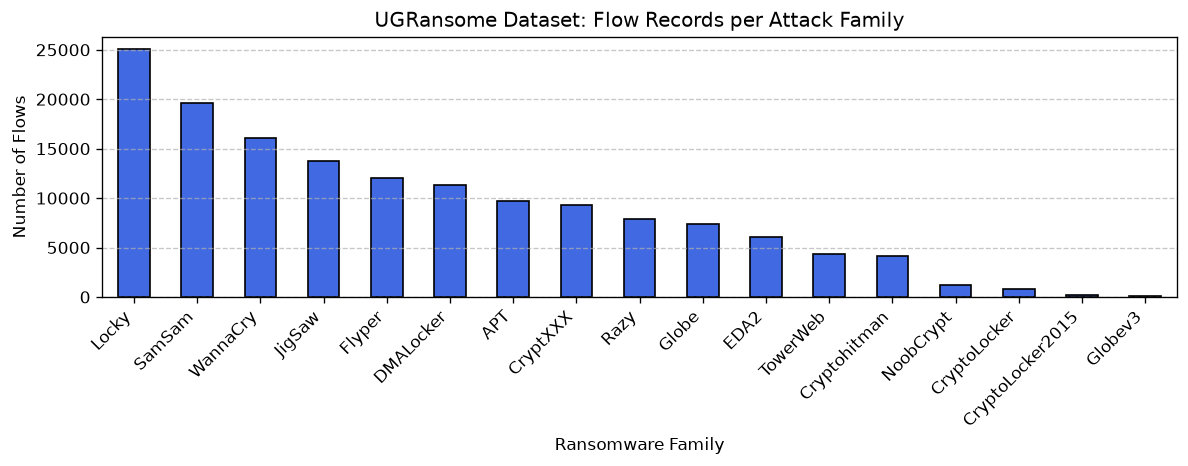

In [2]:
df_raw = pd.read_csv(CONFIG['raw_data_path'])
print(f'[*] Raw Dataset Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')

family_col = 'Family' if 'Family' in df_raw.columns else 'Label'
print(f'\n[*] Target Family Distribution ({df_raw[family_col].nunique()} distinct families):')
family_counts = df_raw[family_col].value_counts()
print(family_counts)

plt.figure(figsize=(10, 4))
family_counts.plot(kind='bar', color='royalblue', edgecolor='black')
plt.title('UGRansome Dataset: Flow Records per Attack Family')
plt.xlabel('Ransomware Family')
plt.ylabel('Number of Flows')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 2. Phase 0 — Feature Sanitization (Anti-Shortcut Leakage)
We strip raw IP addresses (`IPaddress`, `SeddAddress`, `ExpAddress`), ports (`Port`), timestamps (`Time`), and supervisory predictions (`Prediction`, `Threats`). This forces the model to learn true telemetry instead of memorizing network addresses.

In [3]:
def sanitize_features(df, extra_drop_cols=None, keep_cols=None):
    keep_cols_lower = [c.lower() for c in (keep_cols or [])]
    drop_candidates = set(extra_drop_cols or [])
    leakage_patterns = ['ip', 'port', 'timestamp', 'time', 'mac', 'address', 'sedd', 'flow id', 'flow_id']
    for col in df.columns:
        col_lower = col.lower()
        if col_lower in keep_cols_lower:
            continue
        for pattern in leakage_patterns:
            if pattern in col_lower:
                drop_candidates.add(col)
                break
    valid_timing = ['duration', 'iat', 'idle', 'active']
    final_drops = []
    for col in drop_candidates:
        col_lower = col.lower()
        if any(m in col_lower for m in valid_timing) and 'timestamp' not in col_lower:
            continue
        final_drops.append(col)
    return df.drop(columns=final_drops, errors='ignore').copy()

df_sanitized = sanitize_features(df_raw, extra_drop_cols=['Prediction', 'Threats'])
feature_cols = [c for c in df_sanitized.columns if c != family_col]
print(f'[*] Sanitized Features ({len(feature_cols)} total dimensions):')
for i, f in enumerate(feature_cols, 1):
    print(f'    {i:2d}. {f}')

print(f'\n[*] Sanitized DataFrame Shape: {df_sanitized.shape}')

[*] Sanitized Features (6 total dimensions):
     1. Protcol
     2. Flag
     3. Clusters
     4. BTC
     5. USD
     6. Netflow_Bytes

[*] Sanitized DataFrame Shape: (149043, 7)


## 3. Phase 0 — Temporal Windowing & Leave-One-Family-Out (LOFO)
We implement the vectorized sliding window algorithm and the automated LOFO Splitter.
- 100% of the designated family (`WannaCry`) is withheld as the novel zero-day test set.
- Normalization (`StandardScaler`) is fitted strictly on the training partition.

In [4]:
def create_temporal_windows(X, y, window_size=10):
    N, F = X.shape
    if N < window_size:
        raise ValueError(f'Number of samples ({N}) is smaller than window_size ({window_size}).')
    shape = (N - window_size + 1, window_size, F)
    strides = (X.strides[0], X.strides[0], X.strides[1])
    X_windows = np.lib.stride_tricks.as_strided(X, shape=shape, strides=strides)
    y_windows = y[window_size - 1:]
    return torch.tensor(X_windows.copy(), dtype=torch.float32), torch.tensor(y_windows.copy(), dtype=torch.long)

class NetworkTrafficDataset(Dataset):
    def __init__(self, X_windows, y_windows, class_to_idx, benign_label_idx=0):
        self.X_windows = X_windows if isinstance(X_windows, torch.Tensor) else torch.tensor(X_windows, dtype=torch.float32)
        self.y_windows = y_windows if isinstance(y_windows, torch.Tensor) else torch.tensor(y_windows, dtype=torch.long)
        self.class_to_idx = class_to_idx
        self.benign_label_idx = benign_label_idx
    def __len__(self):
        return len(self.X_windows)
    def __getitem__(self, idx):
        return self.X_windows[idx], self.y_windows[idx]

@dataclass
class LOFOFold:
    holdout_family: str
    train_dataset: NetworkTrafficDataset
    val_dataset: NetworkTrafficDataset
    test_known_dataset: NetworkTrafficDataset
    test_unknown_dataset: NetworkTrafficDataset
    val_benign_dataset: NetworkTrafficDataset
    class_to_idx: dict
    num_classes: int
    num_features: int
    scaler: StandardScaler

class LOFOSplitter:
    def __init__(self, df, family_col='Family', benign_label=None, window_size=10, extra_drop_cols=None):
        self.raw_df = df.copy()
        self.family_col = family_col
        self.window_size = window_size
        if 'Protcol' in self.raw_df.columns and 'Protocol' not in self.raw_df.columns:
            self.raw_df.rename(columns={'Protcol': 'Protocol'}, inplace=True)
        unique_labels = self.raw_df[self.family_col].unique().tolist()
        if benign_label is not None and benign_label in unique_labels:
            self.default_benign_label = benign_label
        elif 'BENIGN' in unique_labels:
            self.default_benign_label = 'BENIGN'
        elif 'Benign' in unique_labels:
            self.default_benign_label = 'Benign'
        else:
            self.default_benign_label = None
        if self.default_benign_label is not None:
            self.attack_families = [f for f in unique_labels if f != self.default_benign_label]
        else:
            self.attack_families = unique_labels.copy()
        drop_cols = list(extra_drop_cols or [])
        if 'Prediction' in self.raw_df.columns:
            drop_cols.append('Prediction')
        if 'Threats' in self.raw_df.columns:
            drop_cols.append('Threats')
        self.sanitized_df = sanitize_features(self.raw_df, extra_drop_cols=drop_cols, keep_cols=[self.family_col])

    def get_fold(self, holdout_family, benign_label=None, test_size=0.2, val_size=0.1, scaler_cls=StandardScaler):
        if holdout_family not in self.attack_families:
            raise ValueError(f'Holdout family {holdout_family} not in attack families: {self.attack_families}')
        df_unknown = self.sanitized_df[self.sanitized_df[self.family_col] == holdout_family].copy().sort_index()
        df_known = self.sanitized_df[self.sanitized_df[self.family_col] != holdout_family].copy().sort_index()
        if benign_label is not None:
            active_benign_label = benign_label
        elif self.default_benign_label is not None and self.default_benign_label != holdout_family:
            active_benign_label = self.default_benign_label
        else:
            active_benign_label = df_known[self.family_col].value_counts().index[0]
        known_families = [active_benign_label] + [f for f in df_known[self.family_col].unique() if f != active_benign_label]
        class_to_idx = {name: idx for idx, name in enumerate(known_families)}
        
        train_dfs, val_dfs, test_k_dfs = [], [], []
        for fam in known_families:
            df_fam = df_known[df_known[self.family_col] == fam].sort_index()
            n_f = len(df_fam)
            if n_f < self.window_size + 4:
                train_dfs.append(df_fam)
                continue
            n_te = max(self.window_size, int(n_f * test_size))
            n_va = max(self.window_size, int(n_f * val_size))
            n_tr = n_f - n_te - n_va
            if n_tr < self.window_size:
                n_tr = max(self.window_size, int(n_f * 0.7))
                n_va = n_f - n_tr
                n_te = 0
            train_dfs.append(df_fam.iloc[:n_tr])
            if n_va > 0:
                val_dfs.append(df_fam.iloc[n_tr:n_tr + n_va])
            if n_te > 0:
                test_k_dfs.append(df_fam.iloc[n_tr + n_va:])
        df_train = pd.concat(train_dfs).sort_index().copy()
        df_val = pd.concat(val_dfs).sort_index().copy() if len(val_dfs) > 0 else df_train.copy()
        df_test_known = pd.concat(test_k_dfs).sort_index().copy() if len(test_k_dfs) > 0 else df_val.copy()
        
        y_train_raw = df_train[self.family_col].values
        y_val_raw = df_val[self.family_col].values
        y_test_k_raw = df_test_known[self.family_col].values
        y_test_u_raw = df_unknown[self.family_col].values
        
        X_tr_df = df_train.drop(columns=[self.family_col])
        X_va_df = df_val.drop(columns=[self.family_col])
        X_tk_df = df_test_known.drop(columns=[self.family_col])
        X_tu_df = df_unknown.drop(columns=[self.family_col])
        
        cat_cols = X_tr_df.select_dtypes(include=['object', 'category']).columns.tolist()
        num_cols = X_tr_df.select_dtypes(include=[np.number]).columns.tolist()
        
        if len(cat_cols) > 0:
            ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
            tr_cat = ohe.fit_transform(X_tr_df[cat_cols])
            va_cat = ohe.transform(X_va_df[cat_cols])
            tk_cat = ohe.transform(X_tk_df[cat_cols])
            tu_cat = ohe.transform(X_tu_df[cat_cols])
            names = ohe.get_feature_names_out(cat_cols)
            X_tr_df = pd.concat([X_tr_df[num_cols], pd.DataFrame(tr_cat, columns=names, index=X_tr_df.index)], axis=1)
            X_va_df = pd.concat([X_va_df[num_cols], pd.DataFrame(va_cat, columns=names, index=X_va_df.index)], axis=1)
            X_tk_df = pd.concat([X_tk_df[num_cols], pd.DataFrame(tk_cat, columns=names, index=X_tk_df.index)], axis=1)
            X_tu_df = pd.concat([X_tu_df[num_cols], pd.DataFrame(tu_cat, columns=names, index=X_tu_df.index)], axis=1)
        else:
            X_tr_df = X_tr_df[num_cols]
            X_va_df = X_va_df[num_cols]
            X_tk_df = X_tk_df[num_cols]
            X_tu_df = X_tu_df[num_cols]
            
        scaler = scaler_cls()
        X_tr_scaled = scaler.fit_transform(X_tr_df.values.astype(np.float32))
        X_va_scaled = scaler.transform(X_va_df.values.astype(np.float32))
        X_tk_scaled = scaler.transform(X_tk_df.values.astype(np.float32))
        X_tu_scaled = scaler.transform(X_tu_df.values.astype(np.float32))
        
        y_tr_int = np.array([class_to_idx[c] for c in y_train_raw], dtype=np.int64)
        y_va_int = np.array([class_to_idx[c] for c in y_val_raw], dtype=np.int64)
        y_tk_int = np.array([class_to_idx[c] for c in y_test_k_raw], dtype=np.int64)
        y_tu_int = np.full(len(y_test_u_raw), -1, dtype=np.int64)
        
        X_tr_w, y_tr_w = create_temporal_windows(X_tr_scaled, y_tr_int, self.window_size)
        X_va_w, y_va_w = create_temporal_windows(X_va_scaled, y_va_int, self.window_size)
        X_tk_w, y_tk_w = create_temporal_windows(X_tk_scaled, y_tk_int, self.window_size)
        X_tu_w, y_tu_w = create_temporal_windows(X_tu_scaled, y_tu_int, self.window_size)
        
        benign_idx = class_to_idx[active_benign_label]
        val_b_mask = (y_va_w == benign_idx)
        X_vb_w = X_va_w[val_b_mask]
        y_vb_w = y_va_w[val_b_mask]
        
        return LOFOFold(
            holdout_family=holdout_family,
            train_dataset=NetworkTrafficDataset(X_tr_w, y_tr_w, class_to_idx, benign_idx),
            val_dataset=NetworkTrafficDataset(X_va_w, y_va_w, class_to_idx, benign_idx),
            test_known_dataset=NetworkTrafficDataset(X_tk_w, y_tk_w, class_to_idx, benign_idx),
            test_unknown_dataset=NetworkTrafficDataset(X_tu_w, y_tu_w, class_to_idx, benign_idx),
            val_benign_dataset=NetworkTrafficDataset(X_vb_w, y_vb_w, class_to_idx, benign_idx),
            class_to_idx=class_to_idx,
            num_classes=len(known_families),
            num_features=X_tr_scaled.shape[1],
            scaler=scaler
        )

# Sample representatively across families for interactive efficiency
n_per_fam = 1200
sub_dfs = [group.iloc[:n_per_fam] for _, group in df_raw.groupby(family_col)]
df_sample = pd.concat(sub_dfs).sort_index().copy()

splitter = LOFOSplitter(df=df_sample, family_col=family_col, window_size=CONFIG['window_size'])
fold = splitter.get_fold(holdout_family=CONFIG['holdout_family'])

train_ds = fold.train_dataset
val_ds = fold.val_dataset
val_benign_ds = fold.val_benign_dataset
test_k_ds = fold.test_known_dataset
test_u_ds = fold.test_unknown_dataset

print(f'[*] LOFO Fold Built Successfully:')
print(f'    - Held-Out Zero-Day:     {fold.holdout_family}')
print(f'    - Known Classes ({fold.num_classes}): {list(fold.class_to_idx.keys())}')
print(f'    - Feature Dimensions (F):{fold.num_features}')
print(f'    - Train Windows:         {len(train_ds):,}')
print(f'    - Val Windows:           {len(val_ds):,}')
print(f'    - Val Benign (X_val_b):  {len(val_benign_ds):,} (Reserved for EVT)')
print(f'    - Known Test Windows:    {len(test_k_ds):,}')
print(f'    - Zero-Day Test Windows: {len(test_u_ds):,}')

<string>:109: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
[*] LOFO Fold Built Successfully:
    - Held-Out Zero-Day:     WannaCry
    - Known Classes (16): ['Locky', 'TowerWeb', 'CryptXXX', 'Cryptohitman', 'CryptoLocker', 'NoobCrypt', 'DMALocker', 'Globev3', 'CryptoLocker2015', 'Flyper', 'SamSam', 'Globe', 'EDA2', 'JigSaw', 'APT', 'Razy']
    - Feature Dimensions (F):16
    - Train Windows:         11,618
    - Val Windows:           1,654
    - Val Benign (X_val_b):  120 (Reserved for EVT)
    - Known Test Windows:    3,312
    - Zero-Day Test Windows: 1,191


## 4. Phase 0 — Dirichlet Non-IID Federated Client Partitioning
We implement Dirichlet non-IID partitioning ($\alpha = 0.5$) across $N=3$ edge client nodes. Each client reserves a clean $X_{\text{val\_benign}}$ slice.

[*] Simulated 3 Non-IID Federated Clients:
    Client 0: Train Samples = 4,100, Reserved X_val_b = 42
    Client 1: Train Samples = 2,796, Reserved X_val_b = 41
    Client 2: Train Samples = 4,598, Reserved X_val_b = 41


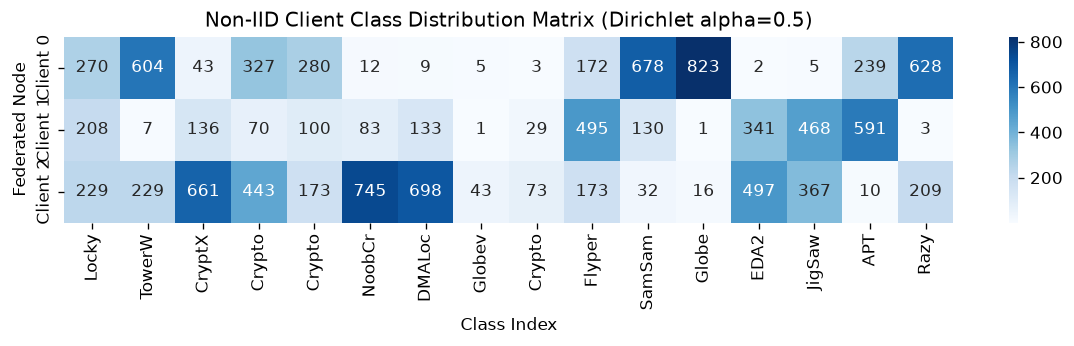

In [5]:
@dataclass
class ClientPartition:
    client_id: int
    train_indices: list
    val_benign_indices: list
    class_counts: dict
    num_train_samples: int
    num_val_benign_samples: int

def dirichlet_partition(dataset, num_clients=3, alpha=0.5, benign_val_ratio=0.15, seed=42):
    rng = np.random.RandomState(seed)
    labels = dataset.y_windows.cpu().numpy()
    num_samples = len(labels)
    benign_idx = dataset.benign_label_idx
    unique_classes = np.unique(labels)
    
    client_train_idx = {i: [] for i in range(num_clients)}
    client_val_b_idx = {i: [] for i in range(num_clients)}
    
    for c in unique_classes:
        c_indices = np.where(labels == c)[0]
        rng.shuffle(c_indices)
        if c == benign_idx and len(c_indices) > num_clients:
            n_val = int(len(c_indices) * benign_val_ratio)
            val_b_split = c_indices[:n_val]
            train_split = c_indices[n_val:]
            client_splits_b = np.array_split(val_b_split, num_clients)
            for i in range(num_clients):
                client_val_b_idx[i].extend(client_splits_b[i].tolist())
            c_indices = train_split
        props = rng.dirichlet(np.repeat(alpha, num_clients))
        counts = np.round(props * len(c_indices)).astype(int)
        diff = len(c_indices) - np.sum(counts)
        counts[np.argmax(counts)] += diff
        cur = 0
        for i, cnt in enumerate(counts):
            if cnt > 0:
                client_train_idx[i].extend(c_indices[cur:cur+cnt].tolist())
                cur += cnt
                
    partitions = []
    for i in range(num_clients):
        tr_idx = client_train_idx[i]
        vb_idx = client_val_b_idx[i]
        c_counts = {}
        if len(tr_idx) > 0:
            u, cnts = np.unique(labels[tr_idx], return_counts=True)
            c_counts = {int(k): int(v) for k, v in zip(u, cnts)}
        partitions.append(ClientPartition(
            client_id=i, train_indices=tr_idx, val_benign_indices=vb_idx,
            class_counts=c_counts, num_train_samples=len(tr_idx), num_val_benign_samples=len(vb_idx)
        ))
    return partitions

client_partitions = dirichlet_partition(train_ds, num_clients=CONFIG['num_clients'], alpha=CONFIG['alpha_dirichlet'])
print(f'[*] Simulated {len(client_partitions)} Non-IID Federated Clients:')
for p in client_partitions:
    print(f'    Client {p.client_id}: Train Samples = {p.num_train_samples:,}, Reserved X_val_b = {p.num_val_benign_samples:,}')

client_mat = np.zeros((CONFIG['num_clients'], fold.num_classes))
for p in client_partitions:
    for c_i, cnt in p.class_counts.items():
        client_mat[p.client_id, c_i] = cnt

plt.figure(figsize=(10, 3))
sns.heatmap(client_mat, annot=True, fmt='.0f', cmap='Blues', 
            xticklabels=[k[:6] for k in fold.class_to_idx.keys()],
            yticklabels=[f'Client {i}' for i in range(CONFIG['num_clients'])])
plt.title('Non-IID Client Class Distribution Matrix (Dirichlet alpha=0.5)')
plt.xlabel('Class Index')
plt.ylabel('Federated Node')
plt.tight_layout()
plt.show()

## 5. Phase 1 — Modular Architecture & Prototype Open-Set Head
We define the abstract base classes `BaseEncoder` and `BaseDecoder`, the `BiLSTMAttentionEncoder`, `LSTMDecoder`, and `PrototypeHead` with learned anchor vectors $\mathbf{c}_k \in \mathbb{R}^d$.

In [6]:
class BaseEncoder(nn.Module, ABC):
    def __init__(self, input_dim, latent_dim, **kwargs):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
    @abstractmethod
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class BaseDecoder(nn.Module, ABC):
    def __init__(self, latent_dim, output_dim, seq_len, **kwargs):
        super().__init__()
        self.latent_dim = latent_dim
        self.output_dim = output_dim
        self.seq_len = seq_len
    @abstractmethod
    def forward(self, z: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1, bias=False)
    def forward(self, lstm_outputs):
        weights = torch.softmax(self.attn(lstm_outputs), dim=1)
        context = torch.sum(weights * lstm_outputs, dim=1)
        return context, weights

class BiLSTMAttentionEncoder(BaseEncoder):
    def __init__(self, input_dim, latent_dim, hidden_dim=64, num_layers=2, dropout=0.1):
        super().__init__(input_dim=input_dim, latent_dim=latent_dim)
        self.bilstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=True, dropout=dropout if num_layers > 1 else 0.0)
        self.attention = TemporalAttention(hidden_dim * 2)
        self.fc_latent = nn.Linear(hidden_dim * 2, latent_dim)
        self.norm = nn.LayerNorm(latent_dim)
    def forward(self, x):
        out, _ = self.bilstm(x)
        ctx, _ = self.attention(out)
        z = self.norm(self.fc_latent(ctx))
        return z

class LSTMDecoder(BaseDecoder):
    def __init__(self, latent_dim, output_dim, seq_len, hidden_dim=64, num_layers=2, dropout=0.1):
        super().__init__(latent_dim=latent_dim, output_dim=output_dim, seq_len=seq_len)
        self.fc_in = nn.Linear(latent_dim, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers=num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.fc_out = nn.Linear(hidden_dim, output_dim)
    def forward(self, z):
        h = self.fc_in(z).unsqueeze(1).repeat(1, self.seq_len, 1)
        out, _ = self.lstm(h)
        return self.fc_out(out)

class PrototypeHead(nn.Module):
    def __init__(self, latent_dim, num_classes, temperature=1.0, eps=1e-7):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.temperature = temperature
        self.eps = eps
        self.prototypes = nn.Parameter(torch.randn(num_classes, latent_dim))
        nn.init.orthogonal_(self.prototypes)
    def forward(self, z):
        B = z.size(0)
        z_exp = z.unsqueeze(1).expand(B, self.num_classes, self.latent_dim)
        proto_exp = self.prototypes.unsqueeze(0).expand(B, self.num_classes, self.latent_dim)
        sq_dist = torch.sum((z_exp - proto_exp) ** 2, dim=-1)
        distances = torch.sqrt(sq_dist + self.eps)
        logits = -distances / self.temperature
        return logits, distances

encoder = BiLSTMAttentionEncoder(input_dim=fold.num_features, latent_dim=CONFIG['latent_dim'], hidden_dim=CONFIG['hidden_dim']).to(DEVICE)
decoder = LSTMDecoder(latent_dim=CONFIG['latent_dim'], output_dim=fold.num_features, seq_len=CONFIG['window_size'], hidden_dim=CONFIG['hidden_dim']).to(DEVICE)
head = PrototypeHead(latent_dim=CONFIG['latent_dim'], num_classes=fold.num_classes).to(DEVICE)

print('[*] Modular Open-Set Architecture Initialized:')
print(f'    Encoder Parameters: {sum(p.numel() for p in encoder.parameters()):,}')
print(f'    Decoder Parameters: {sum(p.numel() for p in decoder.parameters()):,}')
print(f'    Prototype Anchors:  {head.prototypes.shape}')

[*] Modular Open-Set Architecture Initialized:
    Encoder Parameters: 145,632
    Decoder Parameters: 69,712
    Prototype Anchors:  torch.Size([16, 32])


## 6. Phase 1 — Three Joint Losses & Anti-Pollution Training
We formulate $\mathcal{L}_{\text{total}} = \lambda_{\text{rec}} \mathcal{L}_{\text{rec}} + \lambda_{\text{cls}} \mathcal{L}_{\text{cls}} + \lambda_{\text{compact}} \mathcal{L}_{\text{compact}}$.
- $\mathcal{L}_{\text{rec}}$ is computed **STRICTLY on normal benign traffic** via `is_benign_mask`.
- $\mathcal{L}_{\text{compact}}$ pulls known classes tightly around their prototypes.

In [7]:
class FedEVTLoss(nn.Module):
    def __init__(self, lambda_rec=1.0, lambda_cls=1.0, lambda_compact=0.1, eps=1e-8):
        super().__init__()
        self.lambda_rec = lambda_rec
        self.lambda_cls = lambda_cls
        self.lambda_compact = lambda_compact
        self.eps = eps
        self.ce_loss = nn.CrossEntropyLoss()
    def forward(self, logits, distances, x_reconstructed, x_original, y, is_benign_mask):
        if is_benign_mask.any():
            x_rec_b = x_reconstructed[is_benign_mask]
            x_orig_b = x_original[is_benign_mask]
            loss_rec = torch.mean((x_rec_b - x_orig_b) ** 2)
        else:
            loss_rec = torch.tensor(0.0, device=x_original.device)
        loss_cls = self.ce_loss(logits, y)
        batch_idx = torch.arange(y.size(0), device=y.device)
        dist_to_true_proto = distances[batch_idx, y]
        loss_compact = torch.mean(dist_to_true_proto ** 2)
        loss_total = (self.lambda_rec * loss_rec) + (self.lambda_cls * loss_cls) + (self.lambda_compact * loss_compact)
        return loss_total, loss_rec, loss_cls, loss_compact, {}

criterion = FedEVTLoss(lambda_rec=CONFIG['lambda_rec'], lambda_cls=CONFIG['lambda_cls'], lambda_compact=CONFIG['lambda_compact'])
optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()) + list(head.parameters()), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
print('[*] Loss and optimizer initialized.')

[*] Loss and optimizer initialized.


## 7. Model Training Loop
We train the model for 10 epochs. The benign-only mask guarantees that the reconstruction decoder is never polluted by attack flows.

In [8]:
train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=True)
val_benign_loader = DataLoader(val_benign_ds, batch_size=CONFIG['batch_size'], shuffle=False)
test_k_loader = DataLoader(test_k_ds, batch_size=CONFIG['batch_size'], shuffle=False)
test_u_loader = DataLoader(test_u_ds, batch_size=CONFIG['batch_size'], shuffle=False)

benign_idx = fold.train_dataset.benign_label_idx
epochs = CONFIG['epochs']
history = {'total': [], 'rec': [], 'cls': [], 'compact': []}

print(f'[*] Training Local Open-Set Model for {epochs} epochs...')
for epoch in range(1, epochs + 1):
    encoder.train()
    decoder.train()
    head.train()
    ep_total, ep_rec, ep_cls, ep_compact, total_count = 0.0, 0.0, 0.0, 0.0, 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad()
        z = encoder(batch_X)
        logits, distances = head(z)
        x_rec = decoder(z)
        is_benign = (batch_y == benign_idx)
        loss, l_rec, l_cls, l_comp, _ = criterion(logits, distances, x_rec, batch_X, batch_y, is_benign)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(list(encoder.parameters()) + list(decoder.parameters()) + list(head.parameters()), 1.0)
        optimizer.step()
        b_sz = batch_X.size(0)
        ep_total += loss.item() * b_sz
        ep_rec += l_rec.item() * b_sz
        ep_cls += l_cls.item() * b_sz
        ep_compact += l_comp.item() * b_sz
        total_count += b_sz
    avg_tot, avg_rec, avg_cls, avg_comp = ep_total/total_count, ep_rec/total_count, ep_cls/total_count, ep_compact/total_count
    history['total'].append(avg_tot)
    history['rec'].append(avg_rec)
    history['cls'].append(avg_cls)
    history['compact'].append(avg_comp)
    if epoch % 2 == 0 or epoch == 1 or epoch == epochs:
        print(f'    Epoch {epoch:02d}/{epochs:02d} | Total: {avg_tot:.4f} | L_rec(Benign): {avg_rec:.4f} | L_cls: {avg_cls:.4f} | L_compact: {avg_comp:.4f}')

[*] Training Local Open-Set Model for 10 epochs...
    Epoch 01/10 | Total: 4.8354 | L_rec(Benign): 0.1653 | L_cls: 2.3263 | L_compact: 23.4380
    Epoch 02/10 | Total: 3.4182 | L_rec(Benign): 0.0487 | L_cls: 2.0280 | L_compact: 13.4145
    Epoch 04/10 | Total: 1.9927 | L_rec(Benign): 0.0380 | L_cls: 1.5714 | L_compact: 3.8334
    Epoch 06/10 | Total: 1.5638 | L_rec(Benign): 0.0280 | L_cls: 1.3395 | L_compact: 1.9633
    Epoch 08/10 | Total: 1.4563 | L_rec(Benign): 0.0301 | L_cls: 1.2427 | L_compact: 1.8352
    Epoch 10/10 | Total: 1.3973 | L_rec(Benign): 0.0272 | L_cls: 1.1812 | L_compact: 1.8884


## 8. Phase 1 — Fused Novelty Score Engine Calibration
We standardize both reconstruction error ($S_{\text{rec}}$) and nearest prototype distance ($S_{\text{proto}}$) against clean $X_{\text{val\_benign}}$:
$$S_{\text{fused}} = \frac{S_{\text{rec}} - \mu_{\text{rec}}}{\sigma_{\text{rec}}} + \frac{S_{\text{proto}} - \mu_{\text{proto}}}{\sigma_{\text{proto}}}$$

In [9]:
class NoveltyScoreEngine:
    def __init__(self, eps=1e-8):
        self.eps = eps
        self.mu_rec = 0.0
        self.sigma_rec = 1.0
        self.mu_proto = 0.0
        self.sigma_proto = 1.0
    def fit(self, s_rec_benign, s_proto_benign):
        r = np.asarray(s_rec_benign).flatten()
        p = np.asarray(s_proto_benign).flatten()
        self.mu_rec = float(np.mean(r))
        self.sigma_rec = float(np.std(r)) + self.eps
        self.mu_proto = float(np.mean(p))
        self.sigma_proto = float(np.std(p)) + self.eps
        return self
    def transform(self, s_rec, s_proto):
        r = np.asarray(s_rec).flatten()
        p = np.asarray(s_proto).flatten()
        r_norm = (r - self.mu_rec) / self.sigma_rec
        p_norm = (p - self.mu_proto) / self.sigma_proto
        return (r_norm + p_norm), r_norm, p_norm
    def score(self, s_rec, s_proto):
        fused, _, _ = self.transform(s_rec, s_proto)
        return fused

encoder.eval()
decoder.eval()
head.eval()
benign_rec, benign_proto = [], []
with torch.no_grad():
    for batch_X, _ in val_benign_loader:
        batch_X = batch_X.to(DEVICE)
        z = encoder(batch_X)
        x_hat = decoder(z)
        _, dists = head(z)
        mse = torch.mean((x_hat - batch_X) ** 2, dim=(1, 2)).cpu().numpy()
        min_d, _ = torch.min(dists, dim=1)
        benign_rec.extend(mse)
        benign_proto.extend(min_d.cpu().numpy())

novelty_engine = NoveltyScoreEngine().fit(benign_rec, benign_proto)
print(f'[*] Calibration Parameters from X_val_benign:')
print(f'    mu_rec:    {novelty_engine.mu_rec:.5f}, sigma_rec:    {novelty_engine.sigma_rec:.5f}')
print(f'    mu_proto:  {novelty_engine.mu_proto:.5f}, sigma_proto:  {novelty_engine.sigma_proto:.5f}')

[*] Calibration Parameters from X_val_benign:
    mu_rec:    3.00459, sigma_rec:    1.17554
    mu_proto:  0.89601, sigma_proto:  0.07595


## 9. Phase 1 Benchmark Evaluation (AUROC & OSCR)
We evaluate open-set discrimination on held-out **WannaCry** zero-day traffic versus known classes.

In [10]:
def compute_auroc_known_vs_unknown(known_scores, unknown_scores):
    k = np.asarray(known_scores).flatten()
    u = np.asarray(unknown_scores).flatten()
    y_true = np.concatenate([np.zeros(len(k)), np.ones(len(u))])
    y_score = np.concatenate([k, u])
    return float(roc_auc_score(y_true, y_score))

def compute_oscr(known_preds, known_targets, known_scores, unknown_scores):
    ks = np.asarray(known_scores).flatten()
    kp = np.asarray(known_preds).flatten()
    kt = np.asarray(known_targets).flatten()
    us = np.asarray(unknown_scores).flatten()
    n_k, n_u = len(ks), len(us)
    correct_mask = (kp == kt)
    all_s = np.sort(np.unique(np.concatenate([ks, us])))
    if len(all_s) > 1000:
        all_s = np.quantile(all_s, np.linspace(0, 1, 1000))
    ccr_l, fpr_l = [0.0], [0.0]
    for th in all_s:
        ccr_l.append(np.sum((ks <= th) & correct_mask) / n_k)
        fpr_l.append(np.sum(us <= th) / n_u)
    ccr_l.append(float(np.sum(correct_mask) / n_k))
    fpr_l.append(1.0)
    fpr_arr, ccr_arr = np.array(fpr_l), np.array(ccr_l)
    sort_i = np.argsort(fpr_arr)
    fpr_s, ccr_s = fpr_arr[sort_i], ccr_arr[sort_i]
    au = float(np.trapezoid(ccr_s, fpr_s)) if hasattr(np, 'trapezoid') else float(np.trapz(ccr_s, fpr_s))
    return au, fpr_s, ccr_s

def compute_unknown_detection_rate_at_far(known_scores, unknown_scores, target_far=0.01):
    k = np.asarray(known_scores).flatten()
    u = np.asarray(unknown_scores).flatten()
    th = float(np.percentile(k, 100.0 * (1.0 - target_far)))
    det = float(np.mean(u > th))
    return det, th

def extract_scores(loader):
    all_z, all_rec, all_proto, all_preds, all_y = [], [], [], [], []
    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(DEVICE)
            z = encoder(batch_X)
            x_hat = decoder(z)
            logits, dists = head(z)
            mse = torch.mean((x_hat - batch_X) ** 2, dim=(1, 2)).cpu().numpy()
            min_d, _ = torch.min(dists, dim=1)
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            all_z.append(z.cpu().numpy())
            all_rec.extend(mse)
            all_proto.extend(min_d.cpu().numpy())
            all_preds.extend(preds)
            all_y.extend(batch_y.numpy())
    fused = novelty_engine.score(all_rec, all_proto)
    return np.vstack(all_z), np.array(all_rec), np.array(all_proto), fused, np.array(all_preds), np.array(all_y)

z_k, rec_k, proto_k, fused_k, preds_k, y_k = extract_scores(test_k_loader)
z_u, rec_u, proto_u, fused_u, preds_u, y_u = extract_scores(test_u_loader)

benign_mask_k = (y_k == benign_idx)
fused_benign = fused_k[benign_mask_k]

auroc_b_vs_u = compute_auroc_known_vs_unknown(fused_benign, fused_u)
auroc_all_vs_u = compute_auroc_known_vs_unknown(fused_k, fused_u)
au_oscr, oscr_fpr, oscr_ccr = compute_oscr(preds_k, y_k, -fused_k, -fused_u)
det_1pct, thresh_1pct = compute_unknown_detection_rate_at_far(fused_benign, fused_u, target_far=0.01)
det_5pct, thresh_5pct = compute_unknown_detection_rate_at_far(fused_benign, fused_u, target_far=0.05)
acc_closed = np.mean(preds_k == y_k)

print('=' * 65)
print('           FEDEVT-OSAD: PHASE 1 BENCHMARK REPORT             ')
print('=' * 65)
print(f' Held-Out Zero-Day Family:              {fold.holdout_family}')
print(f' Closed-Set Classification Accuracy:    {acc_closed * 100:.2f}%')
print(f' Open-Set AUROC (Benign vs Unknown):    {auroc_b_vs_u:.4f}')
print(f' Open-Set AUROC (All Known vs Unknown): {auroc_all_vs_u:.4f}')
print(f' Open-Set OSCR Area:                    {au_oscr:.4f}')
print(f' Zero-Day Detection @ 1% FAR:           {det_1pct * 100:.2f}% (Threshold: {thresh_1pct:.2f})')
print(f' Zero-Day Detection @ 5% FAR:           {det_5pct * 100:.2f}% (Threshold: {thresh_5pct:.2f})')
print('=' * 65)

           FEDEVT-OSAD: PHASE 1 BENCHMARK REPORT             
 Held-Out Zero-Day Family:              WannaCry
 Closed-Set Classification Accuracy:    23.04%
 Open-Set AUROC (Benign vs Unknown):    0.3011
 Open-Set AUROC (All Known vs Unknown): 0.5586
 Open-Set OSCR Area:                    0.0866
 Zero-Day Detection @ 1% FAR:           0.34% (Threshold: 11.58)
 Zero-Day Detection @ 5% FAR:           0.67% (Threshold: 9.56)


## 10. Visual Analytics & Diagnostic Suite
We plot:
1. **Training Loss Trajectories** ($\mathcal{L}_{\text{total}}, \mathcal{L}_{\text{rec}}, \mathcal{L}_{\text{cls}}, \mathcal{L}_{\text{compact}}$)
2. **PCA Latent Space Geometry**: Showing prototype anchors and cluster tightness.
3. **Open-Set ROC Curves**: Discrimination across false alarm rates.
4. **Novelty Score Histograms**: Clean separation of Benign vs Zero-Day traffic.

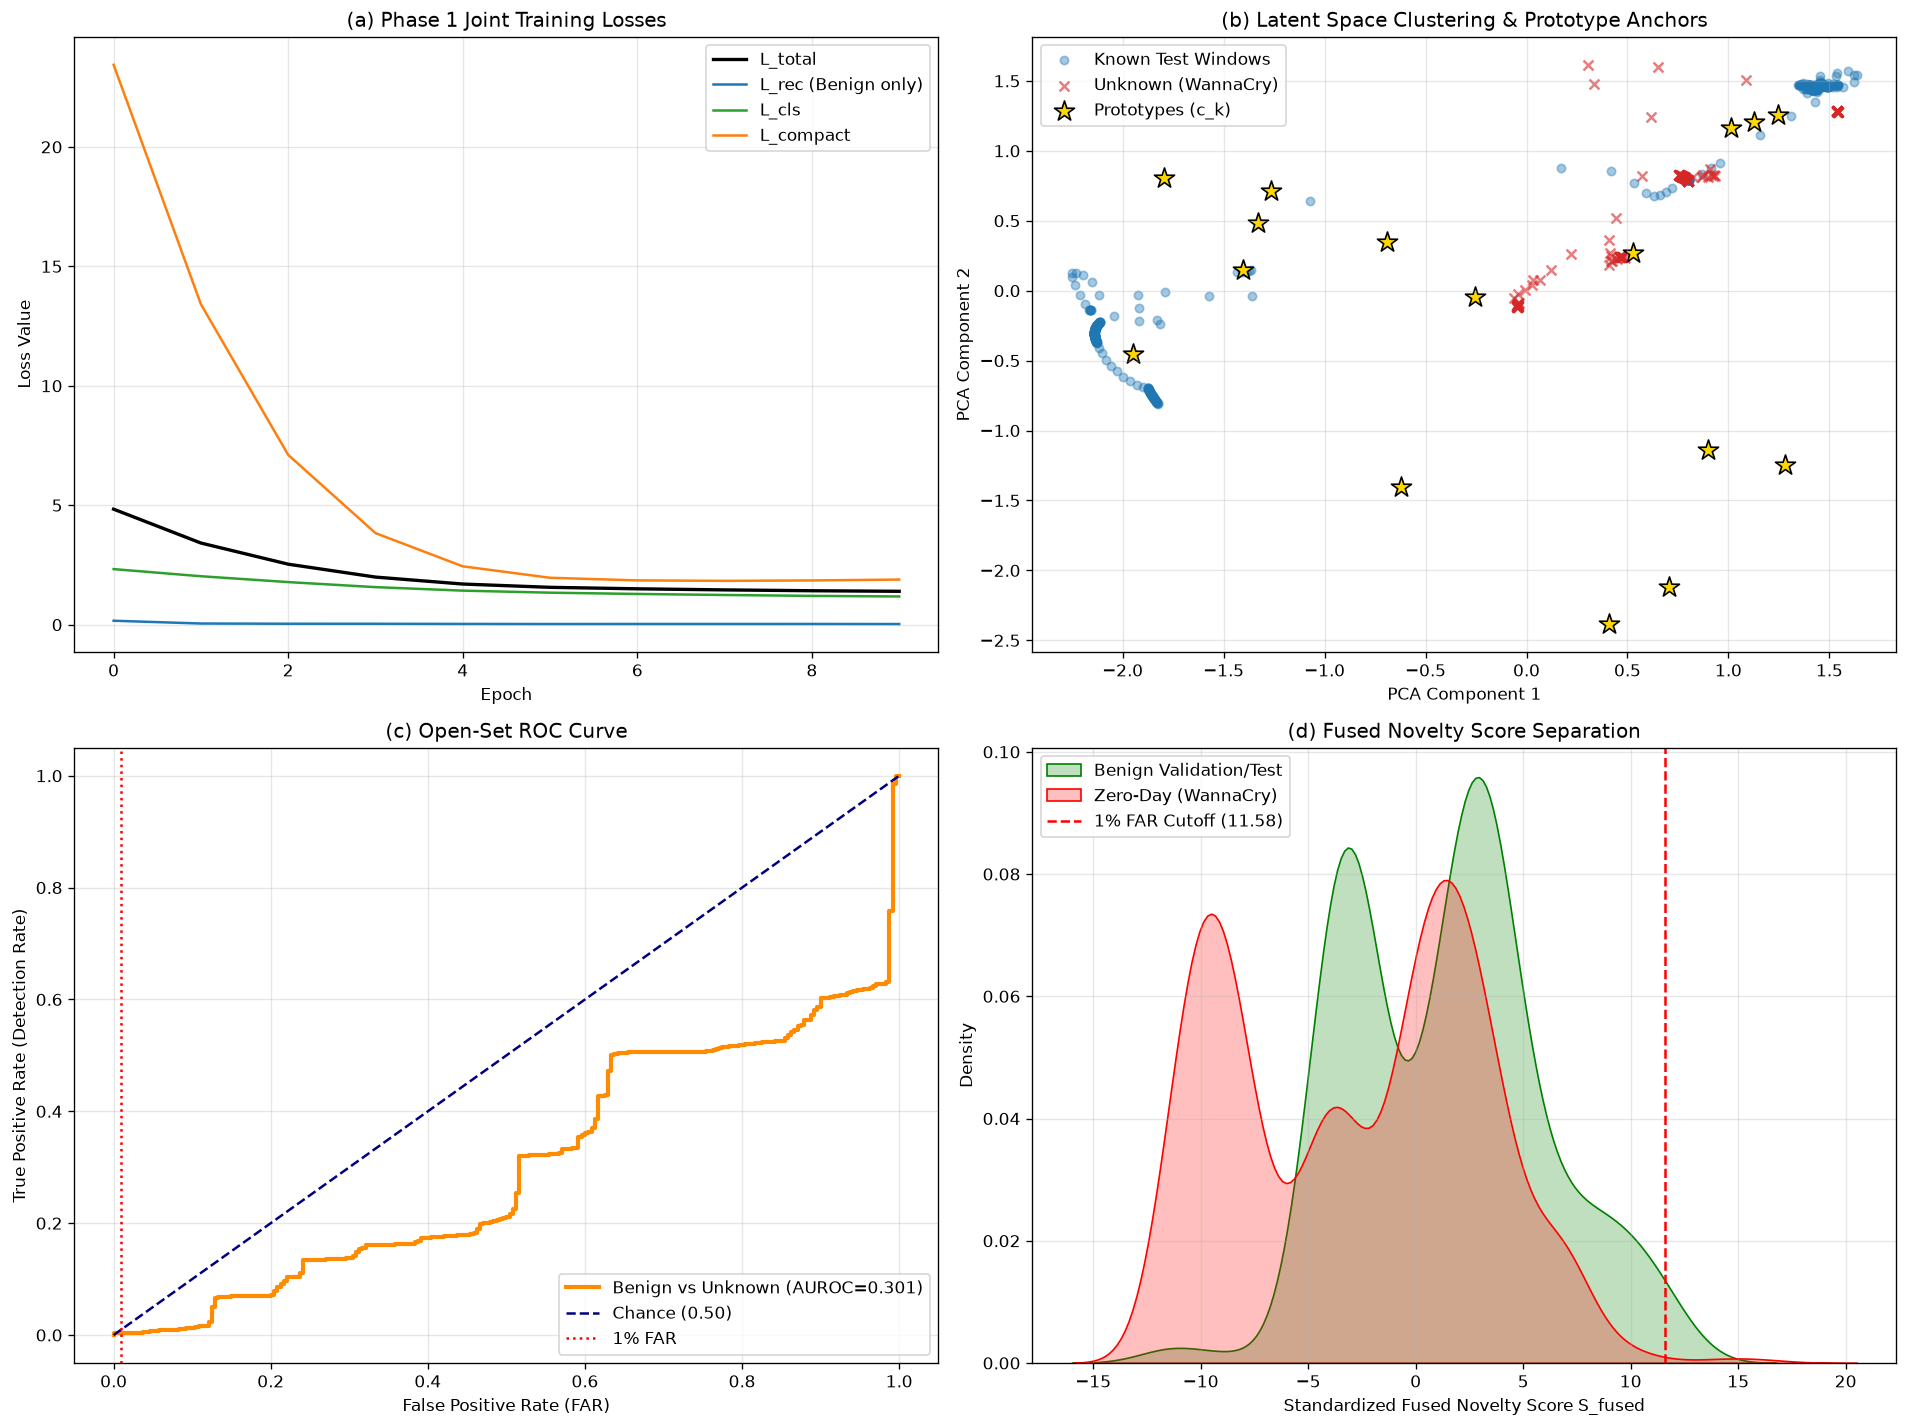

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Loss curves
axes[0, 0].plot(history['total'], label='L_total', color='black', lw=2)
axes[0, 0].plot(history['rec'], label='L_rec (Benign only)', color='tab:blue', lw=1.5)
axes[0, 0].plot(history['cls'], label='L_cls', color='tab:green', lw=1.5)
axes[0, 0].plot(history['compact'], label='L_compact', color='tab:orange', lw=1.5)
axes[0, 0].set_title('(a) Phase 1 Joint Training Losses')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss Value')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Panel 2: PCA Latent Space with Prototypes
pca = PCA(n_components=2, random_state=SEED)
z_prototypes = head.prototypes.detach().cpu().numpy()
pca.fit(z_k)
z_k_2d = pca.transform(z_k[:400])
z_u_2d = pca.transform(z_u[:200])
proto_2d = pca.transform(z_prototypes)

axes[0, 1].scatter(z_k_2d[:, 0], z_k_2d[:, 1], c='tab:blue', alpha=0.4, s=25, label='Known Test Windows')
axes[0, 1].scatter(z_u_2d[:, 0], z_u_2d[:, 1], c='tab:red', alpha=0.6, s=35, marker='x', label=f'Unknown ({fold.holdout_family})')
axes[0, 1].scatter(proto_2d[:, 0], proto_2d[:, 1], c='gold', edgecolors='black', s=160, marker='*', label='Prototypes (c_k)')
axes[0, 1].set_title('(b) Latent Space Clustering & Prototype Anchors')
axes[0, 1].set_xlabel('PCA Component 1')
axes[0, 1].set_ylabel('PCA Component 2')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Panel 3: ROC Curve
y_true_b = np.concatenate([np.zeros(len(fused_benign)), np.ones(len(fused_u))])
scores_b = np.concatenate([fused_benign, fused_u])
fpr_b, tpr_b, _ = roc_curve(y_true_b, scores_b)

axes[1, 0].plot(fpr_b, tpr_b, color='darkorange', lw=2.5, label=f'Benign vs Unknown (AUROC={auroc_b_vs_u:.3f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Chance (0.50)')
axes[1, 0].axvline(0.01, color='red', linestyle=':', label='1% FAR')
axes[1, 0].set_title('(c) Open-Set ROC Curve')
axes[1, 0].set_xlabel('False Positive Rate (FAR)')
axes[1, 0].set_ylabel('True Positive Rate (Detection Rate)')
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(True, alpha=0.3)

# Panel 4: Novelty Score Distribution
sns.kdeplot(fused_benign, ax=axes[1, 1], fill=True, color='green', label='Benign Validation/Test')
sns.kdeplot(fused_u, ax=axes[1, 1], fill=True, color='red', label=f'Zero-Day ({fold.holdout_family})')
axes[1, 1].axvline(thresh_1pct, color='red', linestyle='--', label=f'1% FAR Cutoff ({thresh_1pct:.2f})')
axes[1, 1].set_title('(d) Fused Novelty Score Separation')
axes[1, 1].set_xlabel('Standardized Fused Novelty Score S_fused')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs('results/figures', exist_ok=True)
plt.savefig('results/figures/standalone_verification.png', dpi=150)
plt.show()

## 11. Teammate Guide: Plugging in TCN and Transformer Backbones
Because `BaseEncoder` is defined directly in this notebook, any teammate can plug in their backbone right inside Cell 13:

```python
class TCNEncoder(BaseEncoder):
    def __init__(self, input_dim, latent_dim, num_channels=[64, 64], kernel_size=3):
        super().__init__(input_dim=input_dim, latent_dim=latent_dim)
        # Dilated Causal Convolutions
        ...
    def forward(self, x):
        # (Batch, T, F) -> (Batch, d_latent)
        return z
```
Then instantiate `encoder = TCNEncoder(fold.num_features, CONFIG['latent_dim']).to(DEVICE)`. Everything downstream—the Prototype Head, Benign-only Loss, Dirichlet client slicing, and Fused Novelty Score—remains **100% identical and comparable**.